# Titanic survival prediction

## Imports


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

%matplotlib inline

## Load and inspect the data


In [11]:
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [12]:
df.columns = df.columns.str.lower()

In [13]:
df.describe().round(2)

,passengerid,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


## Prepare features


In [14]:
features = [
    'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'survived'
]
df = df[features].copy()
df['embarked'] = df['embarked'].fillna('Unknown')
df.isnull().sum()

pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      0
survived      0
dtype: int64

In [15]:
df.pclass.value_counts()

pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [16]:
pclass_map = {1: 'first', 2: 'second', 3: 'third'}
df['pclass'] = df['pclass'].map(pclass_map)

In [17]:
df.head()

,pclass,sex,age,sibsp,parch,fare,embarked,survived
0,third,male,22.0,1,0,7.2500,S,0
1,first,female,38.0,1,0,71.2833,C,1
2,third,female,26.0,0,0,7.9250,S,1
3,first,female,35.0,1,0,53.1000,S,1
4,third,male,35.0,0,0,8.0500,S,0


In [18]:
df['family_size'] = df.sibsp + df.parch + 1
df = df.drop(columns=['sibsp', 'parch'])
df.head()

,pclass,sex,age,fare,embarked,survived,family_size
0,third,male,22.0,7.2500,S,0,2
1,first,female,38.0,71.2833,C,1,2
2,third,female,26.0,7.9250,S,1,1
3,first,female,35.0,53.1000,S,1,2
4,third,male,35.0,8.0500,S,0,1


## Split the data and fill missing ages


In [19]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [20]:
mean_age = df_train.age.mean()

df_full_train['age'] = df_full_train.age.fillna(mean_age)
df_train['age'] = df_train.age.fillna(mean_age)
df_val['age'] = df_val.age.fillna(mean_age)
df_test['age'] = df_test.age.fillna(mean_age)

df_train = df_train.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

## Separate targets and vectorize features


In [21]:
y_train = df_train['survived'].to_numpy()
y_val = df_val['survived'].to_numpy()
y_test = df_test['survived'].to_numpy()

train_features = df_train.drop(columns='survived')
val_features = df_val.drop(columns='survived')
test_features = df_test.drop(columns='survived')

In [22]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_features.to_dict(orient='records'))
X_val = dv.transform(val_features.to_dict(orient='records'))

## Decision tree

### Baseline


In [23]:
dt = DecisionTreeClassifier(max_depth=2, random_state=1)
dt.fit(X_train, y_train)
y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.7940767519466074

### Tune depth and minimum leaf size


In [24]:
depths = [1, 2, 3, 5, 10, 15, 20]
samples_leaf = [1, 3, 5, 10, 15, 20, 50, 100, 200, 500]
dt_scores = []
for d in depths:
    for s in samples_leaf:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s, random_state=1)
        dt.fit(X_train, y_train)
        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        dt_scores.append((d, s, auc))
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_dt_scores = pd.DataFrame(dt_scores, columns=columns)
df_dt_scores_pivot = df_dt_scores.pivot(index='min_samples_leaf', columns='max_depth', values='auc')
df_dt_scores_pivot.round(3)

max_depth,1,2,3,5,10,15,20
min_samples_leaf,,,,,,,
1,0.724,0.794,0.839,0.829,0.828,0.772,0.770
3,0.724,0.794,0.839,0.838,0.821,0.817,0.817
5,0.724,0.794,0.840,0.836,0.824,0.832,0.832
10,0.724,0.794,0.838,0.841,0.841,0.841,0.841
15,0.724,0.794,0.842,0.844,0.853,0.853,0.853
20,0.724,0.794,0.842,0.843,0.847,0.847,0.847
50,0.724,0.820,0.822,0.828,0.828,0.828,0.828
100,0.724,0.779,0.788,0.788,0.788,0.788,0.788
200,0.733,0.733,0.733,0.733,0.733,0.733,0.733


<Axes: xlabel='max_depth', ylabel='min_samples_leaf'>

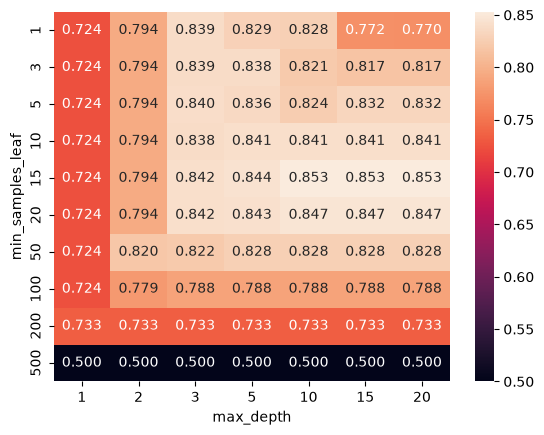

In [25]:
sns.heatmap(df_dt_scores_pivot, annot=True, fmt='.3f')

### Selected decision tree


In [26]:
dt_max_depth = 15
dt_min_samples_leaf = 15

best_dt = DecisionTreeClassifier(
    max_depth=dt_max_depth,
    min_samples_leaf=dt_min_samples_leaf,
    random_state=1,
)

## Random forest


### Tune depth and number of trees


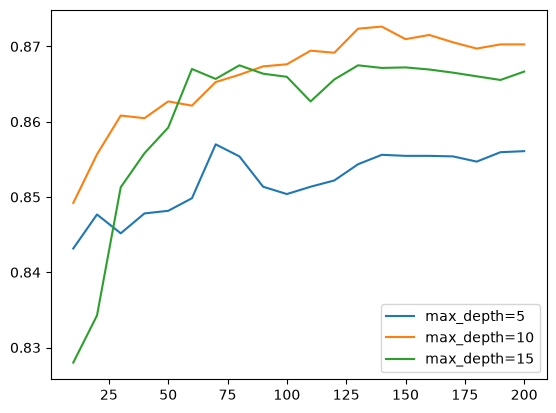

In [27]:
rf_scores = []
tuned_depths = [5, 10, 15]

for d in tuned_depths:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                max_depth=d,
                                random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        rf_scores.append((d, n, auc))
columns = ['max_depth', 'n_estimators', 'auc']
df_rf_scores = pd.DataFrame(rf_scores, columns=columns)

for d in tuned_depths:
    df_subset = df_rf_scores[df_rf_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.legend()

In [28]:
rf_max_depth = 10

### Tune minimum leaf size and number of trees


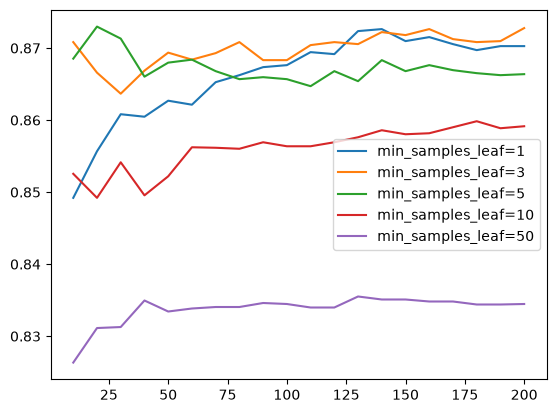

In [29]:
rf_scores = []
samples_leaf = [1, 3, 5, 10, 50]

for s in samples_leaf:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, random_state=1, max_depth=rf_max_depth, min_samples_leaf=s)
        rf.fit(X_train, y_train)
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        rf_scores.append((s, n, auc))
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_rf_scores = pd.DataFrame(rf_scores, columns=columns)
for s in samples_leaf:
    df_subset = df_rf_scores[df_rf_scores.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='min_samples_leaf=%d' % s)
plt.legend()

### Selected random forest


In [30]:
rf_min_samples_leaf = 3

In [31]:
best_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=rf_max_depth,
    min_samples_leaf=rf_min_samples_leaf,
    random_state=1,
)

## XGBoost


### Prepare XGBoost data


In [32]:
feature_names = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)

watchlist = [(dtrain, 'train'), (dval, 'val')]

### Tune eta


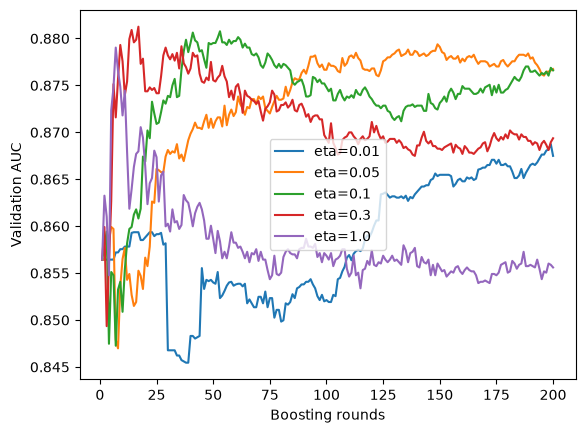

In [33]:
# Train XGBoost models for each eta and store AUC results
eta_scores = {}
etas = [0.01, 0.05, 0.1, 0.3, 1.0]

for eta in etas:
    evals_result = {}

    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }

    xgb.train(
        xgb_params,
        dtrain,
        evals=watchlist,
        verbose_eval=0,
        num_boost_round=200,
        evals_result=evals_result
    )

    columns = ['iter', 'train_auc', 'val_auc']
    train_aucs = evals_result['train']['auc']
    val_aucs = evals_result['val']['auc']

    df_results = pd.DataFrame(
        list(zip(range(1, len(train_aucs) + 1), train_aucs, val_aucs)),
        columns=columns
    )

    key = f'eta={eta}'
    eta_scores[key] = df_results

plt.figure()
for key, df_score in eta_scores.items():
    plt.plot(df_score['iter'], df_score['val_auc'], label=key)

plt.xlabel('Boosting rounds')
plt.ylabel('Validation AUC')
plt.legend()
plt.show()

In [34]:
best_eta = 0.3

### Tune maximum depth


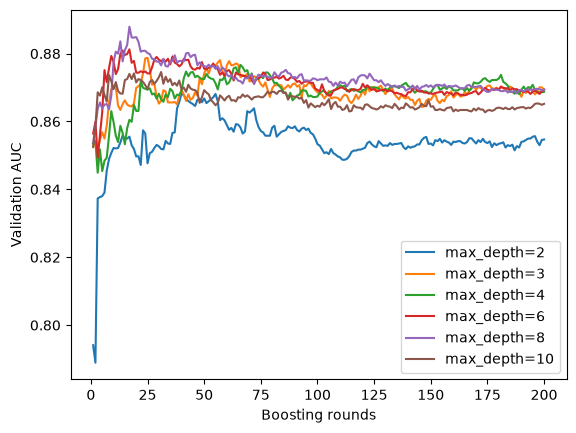

In [35]:
# Train XGBoost models for each max_depth and store AUC results
depth_scores = {}
depths = [2, 3, 4, 6, 8, 10]

for depth in depths:
    evals_result = {}

    xgb_params = {
        'eta': best_eta,
        'max_depth': depth,
        'min_child_weight': 1,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }

    xgb.train(
        xgb_params,
        dtrain,
        evals=watchlist,
        verbose_eval=0,
        num_boost_round=200,
        evals_result=evals_result
    )

    columns = ['iter', 'train_auc', 'val_auc']
    train_aucs = evals_result['train']['auc']
    val_aucs = evals_result['val']['auc']

    df_results = pd.DataFrame(
        list(zip(range(1, len(train_aucs) + 1), train_aucs, val_aucs)),
        columns=columns
    )

    key = f'max_depth={depth}'
    depth_scores[key] = df_results

plt.figure()
for key, df_score in depth_scores.items():
    plt.plot(df_score['iter'], df_score['val_auc'], label=key)

plt.xlabel('Boosting rounds')
plt.ylabel('Validation AUC')
plt.legend()
plt.show()

In [36]:
best_max_depth = 8

### Tune minimum child weight


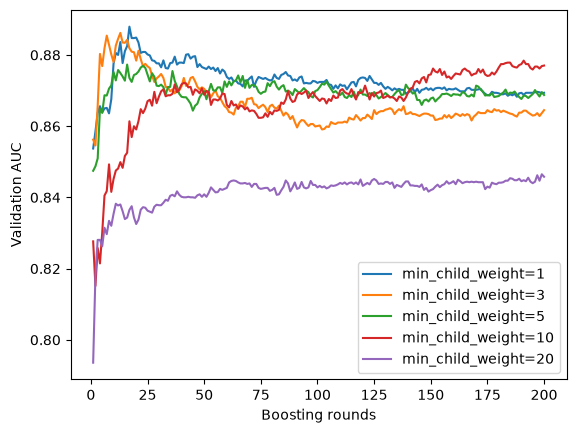

In [37]:
# Train XGBoost models for each min_child_weight and store AUC results
child_weight_scores = {}
child_weights = [1, 3, 5, 10, 20]

for weight in child_weights:
    evals_result = {}

    xgb_params = {
        'eta': best_eta,
        'max_depth': best_max_depth,
        'min_child_weight': weight,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }

    xgb.train(
        xgb_params,
        dtrain,
        evals=watchlist,
        verbose_eval=0,
        num_boost_round=200,
        evals_result=evals_result
    )

    columns = ['iter', 'train_auc', 'val_auc']
    train_aucs = evals_result['train']['auc']
    val_aucs = evals_result['val']['auc']

    df_results = pd.DataFrame(
        list(zip(range(1, len(train_aucs) + 1), train_aucs, val_aucs)),
        columns=columns
    )

    key = f'min_child_weight={weight}'
    child_weight_scores[key] = df_results

plt.figure()
for key, df_score in child_weight_scores.items():
    plt.plot(df_score['iter'], df_score['val_auc'], label=key)

plt.xlabel('Boosting rounds')
plt.ylabel('Validation AUC')
plt.legend()
plt.show()

In [38]:
best_min_child_weight = 1
num_boost_round = 17

### Train the selected XGBoost model


In [39]:
best_xgb_params = {
    'eta': best_eta,
    'max_depth': best_max_depth,
    'min_child_weight': best_min_child_weight,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

best_xgb = xgb.train(
    best_xgb_params,
    dtrain,
    num_boost_round=num_boost_round,
)

## Compare models on validation data


### Decision tree validation AUC


In [40]:
best_dt.fit(X_train, y_train)
y_pred = best_dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.8528921023359288

### Random forest validation AUC


In [41]:
best_rf.fit(X_train, y_train)
y_pred = best_rf.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.8727753058954394

### XGBoost validation AUC


In [42]:
y_pred = best_xgb.predict(dval)
roc_auc_score(y_val, y_pred)

0.8879310344827587

## Final training and saving

Final training, test evaluation, and saving are in [train.py](train.py).
Run `uv run python train.py` from the project directory to create `model.bin`.
The file contains the fitted vectorizer, XGBoost model, and missing-age mean.